In [ ]:
# use datacq kernel

import getpass
import hashlib
import json
import os
import random
import time
from pathlib import Path

import pandas as pd
import requests
from requests.structures import CaseInsensitiveDict
from dotenv import load_dotenv 



ROOT_DIR = Path.cwd().parent

load_dotenv(ROOT_DIR / ".env")

CACHE = ROOT_DIR / "cache"
CACHE.mkdir(exist_ok=True)
FIXTURES = Path("fixtures")

DATA_DIR = ROOT_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

### Credentials input


In [2]:
# endpoints
TOKEN_URL = "https://id.twitch.tv/oauth2/token"
GAMES_URL = "https://api.twitch.tv/helix/games/top"
CLIPS_URL = "https://api.twitch.tv/helix/clips"
CHANNELS_URL = "https://api.twitch.tv/helix/channels"

# credentials
CLIENT_ID = os.environ.get("TWITCH_CLIENT_ID")
CLIENT_SECRET = os.environ.get("TWITCH_CLIENT_SECRET")

if not CLIENT_ID:
    CLIENT_ID = getpass.getpass("Twitch Client ID: ")
if not CLIENT_SECRET:
    CLIENT_SECRET = getpass.getpass("Twitch Client Secret: ")

In [3]:
OFFLINE = os.environ.get("OFFLINE") == "1"
POLITE_DELAY = 0.0 if OFFLINE else 1.0   # seconds between live requests


def cache_key(url, params=None):
    """A short, stable name for one (url, params) pair.
    """
    payload = url + "|" + json.dumps(params or {}, sort_keys=True)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]


class FixtureResponse:

    def __init__(self, record):
        self.url = record.get("final_url", record["url"])
        self.status_code = record["status_code"]
        self.headers = CaseInsensitiveDict(record["headers"])
        self._body = record["body"]

    def json(self):
        return self._body

    @property
    def links(self):
        header = self.headers.get("link")
        if not header:
            return {}
        return {l["rel"]: l for l in requests.utils.parse_header_links(header)}

    def raise_for_status(self):
        if self.status_code >= 400:
            raise requests.HTTPError(f"{self.status_code} for {self.url}")


def offline_get(url, params=None, **kwargs):
    path = FIXTURES / f"{cache_key(url, params)}.json"
    if not path.exists():
        raise RuntimeError(
            f"no fixture for {url} {params}")
    return FixtureResponse(json.loads(path.read_text()))

if OFFLINE:
    requests.get = offline_get
    print("OFFLINE:", len(list(FIXTURES.glob("*.json"))), "fixtures loaded")
else:
    print("live requests")

live requests


### Token exchange

In [4]:
def get_oauth_token(cid, secret):
  payload = {
      "client_id": cid,
      "client_secret": secret,
      "grant_type": "client_credentials",
  }
  r = requests.post(TOKEN_URL, data=payload, timeout=10)
  r.raise_for_status()
  return r.json()["access_token"]


TOKEN = get_oauth_token(CLIENT_ID, CLIENT_SECRET) if not OFFLINE else "mock_token"

HEADERS = {"Client-Id": CLIENT_ID, "Authorization": f"Bearer {TOKEN}"}

In [ ]:
def http_get(url, params=None, headers=HEADERS, attempts=5):
    for k in range(attempts):
        try:
            r = requests.get(url, params=params, headers=headers,
                             timeout=10)
        except requests.RequestException as exc:   # timeout, DNS, reset
            status, retry_after = repr(exc), 0
        else:
            # 200 -> return the parsed body
            if (r.status_code == 200):
                return r.json()

            # status that will not change -> raise_for_status()
            if r.status_code not in (429, 500, 502, 503, 504):
                r.raise_for_status()


            # otherwise remember the status, and read Ratelimit-Reset
            status = r.status_code
            retry_after = 0
            if "Ratelimit-Reset" in r.headers:
                try:    
                    reset_epoch = int(r.headers["Ratelimit-Reset"])
                    retry_after = max(0, reset_epoch - int(time.time()))
                except (ValueError, TypeError):
                    retry_after = 0


        if k + 1 < attempts:

            if retry_after > 0:
                wait = retry_after
            else:
                wait = random.uniform(0, 2**k)

            print(f"  {status} on attempt {k + 1}, sleeping {wait:.1f}s")
            time.sleep(wait)
            
    raise RuntimeError(f"gave up after {attempts} attempts: {url}")


In [6]:
requests_made = 0


def cached_get(url, params=None):
    path = CACHE / f"{cache_key(url, params)}.json"
    if path.exists():
        return json.loads(path.read_text())

    global requests_made
    requests_made += 1
    body = http_get(url, params)
    path.write_text(json.dumps(body))
    time.sleep(POLITE_DELAY)
    return body

### Fetch games and clips loop

In [ ]:
# fetch the top games
games_params = {"first": 20}
games_data = cached_get(GAMES_URL, params=games_params)
top_games = games_data.get("data", [])

print(f"collected {len(top_games)} top game categories.")

# fetch the most viewed clips for each game in september
clips = []

for game in top_games:
    params = {
        "game_id": game["id"],
        "started_at": "2026-09-01T00:00:00Z",
        "ended_at": "2026-09-30T23:59:59Z",
        "first": 100 # twitch api returns clips ordered by view count by default
    }
    
    data = cached_get(CLIPS_URL, params=params)
    game_clips = data.get("data", [])
    
    clips.extend(game_clips)
    print(f"collected {len(game_clips)} clips for game: {game['name']}")

print(f"\ntotal clips collected: {len(clips)}")

collected 20 top game categories.
collected 100 clips for game: Just Chatting
collected 99 clips for game: League of Legends
collected 99 clips for game: Grand Theft Auto V
collected 97 clips for game: World of Warcraft
collected 99 clips for game: EA Sports FC 27
collected 100 clips for game: Fortnite
collected 100 clips for game: AION 2
collected 100 clips for game: Counter-Strike
collected 100 clips for game: Rainbow Six Siege
collected 100 clips for game: VALORANT
collected 100 clips for game: IRL
collected 100 clips for game: Dota 2
collected 99 clips for game: Minecraft
collected 100 clips for game: Street Fighter 6
collected 100 clips for game: Slots
collected 100 clips for game: Rust
collected 100 clips for game: Overwatch
collected 99 clips for game: Among Us
collected 100 clips for game: Marvel Rivals
collected 0 clips for game: CreatorSMP

total clips collected: 1892


### Fetch broadcasters loop

Here we get user metadata in batches of 100 to avoid hitting rate limit


In [8]:
# extract unique broadcaster ids from the clips
broadcaster_ids = list(dict.fromkeys(c["broadcaster_id"] for c in clips))
channels = []

BATCH_SIZE = 100
for i in range(0, len(broadcaster_ids), BATCH_SIZE):
    chunk = broadcaster_ids[i : i + BATCH_SIZE]
    
    # the channels endpoint accepts multiple broadcaster ids
    params = [("broadcaster_id", uid) for uid in chunk]

    data = cached_get(CHANNELS_URL, params=params)
    channels.extend(data.get("data", []))

print(f"channel profiles collected: {len(channels)}")

channel profiles collected: 786


### Storing the dataset and the log

In [ ]:
from datetime import datetime, timezone

# create dataframes
df_games = pd.json_normalize(top_games)
df_clips = pd.json_normalize(clips)
df_channels = pd.json_normalize(channels)

# remove personal data for GDPR compliance
df_clips = df_clips.drop(columns=["creator_id", "broadcaster_name", "creator_name"])
df_channels = df_channels.drop(columns=["broadcaster_login", "broadcaster_name"])


games_path = DATA_DIR / "games.parquet"
clips_path = DATA_DIR / "clips.parquet"
channels_path = DATA_DIR / "channels.parquet"

# save parquet files 
df_games.to_parquet(games_path, index=False)
df_clips.to_parquet(clips_path, index=False)
df_channels.to_parquet(channels_path, index=False)

log = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "api_version": "Twitch Helix",
    "endpoints": [GAMES_URL, CLIPS_URL, CHANNELS_URL],
    "scope_revision": "Twitch: The 100 most viewed clips from each of the top 20 game categories created between September 1 and 30, 2026, including view count, duration, language, and channel tags.",
    "parameters": {
        "clip_started_at": "2026-09-01T00:00:00Z",
        "clip_ended_at": "2026-09-30T23:59:59Z",
        "games_limit": 20,
        "clips_per_game": 100
    },
    "collected_counts": {
        "games": len(df_games),
        "clips": len(df_clips),
        "channels": len(df_channels),
    },
    "shapes": {
        "games_parquet": list(df_games.shape),
        "clips_parquet": list(df_clips.shape),
        "channels_parquet": list(df_channels.shape),
    },
    "storage_files": [str(games_path), str(clips_path), str(channels_path)],
}

log_path = ROOT_DIR / "acquisition_log.json"
Path(log_path).write_text(json.dumps(log, indent=2))
print(f"acquisition log written to: {log_path}")

acquisition log written to: c:\Users\natha\OneDrive\Desktop\Coding\M1AI\twitch_live_datacq\acquisition_log.json


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 100)
sns.set_theme(style="whitegrid")

FINDINGS = Path("findings.md")
channels = Path("../data/channels.parquet")
clips = Path("../data/clips.parquet")
games = Path("../data/games.parquet")

chdf = pd.read_parquet(channels)
cdf = pd.read_parquet(clips)
gdf = pd.read_parquet(games)

# make sure no personal data is present for GDPR compliance
# check that these columns should already have been removed in previous notebook:
chdf_personal_columns=["broadcaster_login", "broadcaster_name"]
cdf_personal_columns=["creator_id", "broadcaster_name", "creator_name"]

for col in chdf_personal_columns:
    if col in chdf.columns:
        print(f"Warning: Personal data column '{col}' found in channels dataframe.")
for col in cdf_personal_columns:
    if col in cdf.columns:
        print(f"Warning: Personal data column '{col}' found in clips dataframe.")

print("channels : ", chdf.shape[0], "rows,", chdf.shape[1], "columns")
print("clips : ", cdf.shape[0], "rows,", cdf.shape[1], "columns")
print("games : ", gdf.shape[0], "rows,", gdf.shape[1], "columns")

channels :  786 rows, 11 columns
clips :  1892 rows, 17 columns
games :  20 rows, 4 columns


In [2]:
cdf.dtypes

id                   object
url                  object
embed_url            object
broadcaster_id       object
broadcaster_name     object
creator_id           object
creator_name         object
video_id             object
game_id              object
language             object
title                object
view_count            int64
created_at           object
thumbnail_url        object
duration            float64
vod_offset          float64
is_featured            bool
dtype: object

### Transforming the data

In [3]:
# remove uncessary columns
cdf = cdf.drop(columns=["thumbnail_url", "url", "embed_url"])
gdf = gdf.drop(columns=["box_art_url"])

# now we transform variables to proper types
chdf['broadcaster_id'] = pd.to_numeric(chdf["broadcaster_id"], errors="coerce").astype("Int64")
chdf['game_id'] = pd.to_numeric(chdf["game_id"], errors="coerce").astype("Int64")
chdf['game_name'] = chdf['game_name'].astype("string")
chdf['broadcaster_language'] = chdf['broadcaster_language'].astype("string")
chdf['title'] = chdf['title'].astype("string")
# Here we parse the tags column, which is a comma-separated string of tags, into a list of strings.
chdf["tags"] = chdf["tags"].astype("string")
chdf['tags'] = chdf['tags'].str.split(",").apply(lambda x: [item.strip() for item in x] if isinstance(x, list) else x)

# parse labels column, which is a comma-separated string of labels, into a list of strings.
chdf['content_classification_labels'] = chdf['content_classification_labels'].astype("string")
chdf['content_classification_labels'] = chdf['content_classification_labels'].str.split(",").apply(lambda x: [item.strip() for item in x] if isinstance(x, list) else x)


# Clip IDs are strings
cdf["id"] = cdf["id"].astype("string")
cdf["broadcaster_id"] = pd.to_numeric(cdf["broadcaster_id"], errors="coerce").astype("Int64")
cdf["video_id"] = pd.to_numeric(cdf["video_id"], errors="coerce").astype("Int64")
cdf["game_id"] = pd.to_numeric(cdf["game_id"], errors="coerce").astype("Int64")
cdf["language"] = cdf["language"].astype("string")
cdf["title"] = cdf["title"].astype("string")
# Quantitative / Numerical features
cdf["view_count"] = pd.to_numeric(cdf["view_count"], errors="coerce").astype("Int64")
cdf["duration"] = pd.to_numeric(cdf["duration"], errors="coerce").astype("Float64")
# vod_offset is in seconds; Int64 accommodates clips where VOD no longer exists (null)
cdf["vod_offset"] = pd.to_numeric(cdf["vod_offset"], errors="coerce").astype("Int64")
cdf["created_at"] = pd.to_datetime(cdf["created_at"], utc=True)
cdf["is_featured"] = cdf["is_featured"].astype("boolean")

gdf["id"] = pd.to_numeric(gdf["id"], errors="coerce").astype("Int64")
gdf["name"] = gdf["name"].astype("string")
gdf["igdb_id"] = pd.to_numeric(gdf["igdb_id"], errors="coerce").astype("Int64")


print("channels dtypes:")
print(chdf.dtypes.to_string())
print("\nclips dtypes:")
print(cdf.dtypes.to_string())
print("\ngames dtypes:")
print(gdf.dtypes.to_string())

channels dtypes:
broadcaster_id                            Int64
broadcaster_login                        object
broadcaster_name                         object
broadcaster_language             string[python]
game_id                                   Int64
game_name                        string[python]
title                            string[python]
delay                                     int64
tags                                     object
content_classification_labels            object
is_branded_content                         bool

clips dtypes:
id                       string[python]
broadcaster_id                    Int64
broadcaster_name                 object
creator_id                       object
creator_name                     object
video_id                          Int64
game_id                           Int64
language                 string[python]
title                    string[python]
view_count                        Int64
created_at          datetime64[ns, UTC]


In [4]:
# estimators of quantitative vars
print("delay descriptors : ", chdf['delay'].describe().round(2).to_string())
print("view_count descriptors : ", cdf['view_count'].describe().round(2).to_string())
print("duration descriptors : ", cdf['duration'].describe().round(2).to_string())
print("vod_offset descriptors : ", cdf['vod_offset'].describe().round(2).to_string())



delay descriptors :  count    786.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
view_count descriptors :  count      1892.0
mean      8688.36
std       12706.2
min         249.0
25%       1982.25
50%        4651.0
75%      10042.75
max      153148.0
duration descriptors :  count    1892.0
mean      26.66
std       17.55
min         4.9
25%        11.2
50%        23.4
75%       35.82
max        60.0
vod_offset descriptors :  count      1607.0
mean     12144.79
std      14663.93
min          93.0
25%        3695.5
50%        8301.0
75%       15447.5
max      163764.0


we see that delay is 0 for all. This isn't very interesting, we will remove it from the df:

In [5]:
chdf = chdf.drop(columns =['delay'])

### Identifying collumns with missing values : 

In [6]:
for(df, name) in [(chdf, "channels"), (cdf, "clips"), (gdf, "games")]:
    print(f"\n{name} missing values:")
    missing = df.isna().sum()
    missing = missing[missing > 0]
    percentage_missing = (missing / df.shape[0]) * 100
    print(missing.to_string(),"\n\nPercentage of missing values:\n",  percentage_missing.round(2).to_string())



channels missing values:
game_id    5 

Percentage of missing values:
 game_id    0.64

clips missing values:
video_id      285
vod_offset    285 

Percentage of missing values:
 video_id      15.06
vod_offset    15.06

games missing values:
igdb_id    6 

Percentage of missing values:
 igdb_id    30.0


we see that igdb_id for game df, as well as video_id and vod_offset for clips df, are missing at high percentage. Furthermore, video_id and vod_offset are missing at the same rate, leading us to wonder if this is linked.

we should consider investigating the link :

In [7]:
both_missing = cdf["video_id"].isna() & cdf["vod_offset"].isna()
one_missing = cdf["video_id"].isna() ^ cdf["vod_offset"].isna()

print(f"Rows where both are missing: {both_missing.sum()}")
print(f"Rows where only one is missing: {one_missing.sum()}")

Rows where both are missing: 285
Rows where only one is missing: 0


this confirms our intuition. After some research, we learn that in Twitch's architecture, if a broadcaster does not archive past broadcasts (VODs) or if the 14–60 day VOD retention window expires, Twitch drops both the source video_id and the vod_offset simultaneously, while keeping the clip itself.

we also found that the missing igdb_id is for linking to Internet Game Database, to get game metadata. This is outside of our scope.

In any case these columns are not interesting to use. We also notice that clip id collumn is a randomly generate string of no interest to us. We can delete them :

In [8]:
cdf = cdf.drop(columns=["video_id", "vod_offset", "id"])
gdf = gdf.drop(columns=["igdb_id"])

## Looking for impossible, extreme, ambiguous values

In [9]:
impossible_clips = (
    (cdf["duration"] <= 0)                      # Clip has zero or negative duration
    | (cdf["duration"] > 60)                   #  Twitch clip minimum length is 5s, max is 60
    | (cdf["view_count"] < 0)                   # no egative views
    | (cdf["created_at"] > pd.Timestamp.now(tz="UTC"))  # Future timestamps or timestaps that are too old
    | (cdf["created_at"] < pd.Timestamp("2015-01-01", tz="UTC"))  # Timestamps that are too old
)

ambiguous_clips = (
    (cdf["view_count"] == 0)                    # Zero views (dead clip or tracking delay)
    | (cdf["duration"] < 5.0)                   #  Twitch clip minimum length is 5s, max is 60
    | (cdf["view_count"] > 1000000)           # Extreme outlier
)

print(f"Impossible rows  : {impossible_clips.sum():,} ({impossible_clips.mean():.2%})")
print(f"Ambiguous rows   : {ambiguous_clips.sum():,} ({ambiguous_clips.mean():.2%})")
print(f"Clean rows       : {(~(impossible_clips | ambiguous_clips)).sum():,} ({(~(impossible_clips | ambiguous_clips)).mean():.2%})\n")

if ambiguous_clips.any():
    print("Sample ambiguous clips:")
    print(cdf.loc[ambiguous_clips, ["title", "duration", "view_count", "duration"]].head())

Impossible rows  : 0 (0.00%)
Ambiguous rows   : 58 (3.07%)
Clean rows       : 1,834 (96.93%)

Sample ambiguous clips:
                 title  duration  view_count  duration
3     CLAIM THAT WOMAN       4.9      100488       4.9
11               зачем       4.9       65991       4.9
17                オカズ🦶       4.9       55710       4.9
18       he just nuted       4.9       54138       4.9
27  i am not good girl       4.9       39385       4.9


No impossible data. We see that the ambiguous probelem is a duration of 4.9. This seems ok, because min duration is 5 so it's a small error we don't care about.

This means our data frames are clean!

## temporal patterns

First clip created at : 2026-09-01 00:50:29+00:00
Last clip created at  : 2026-09-30 23:42:23+00:00


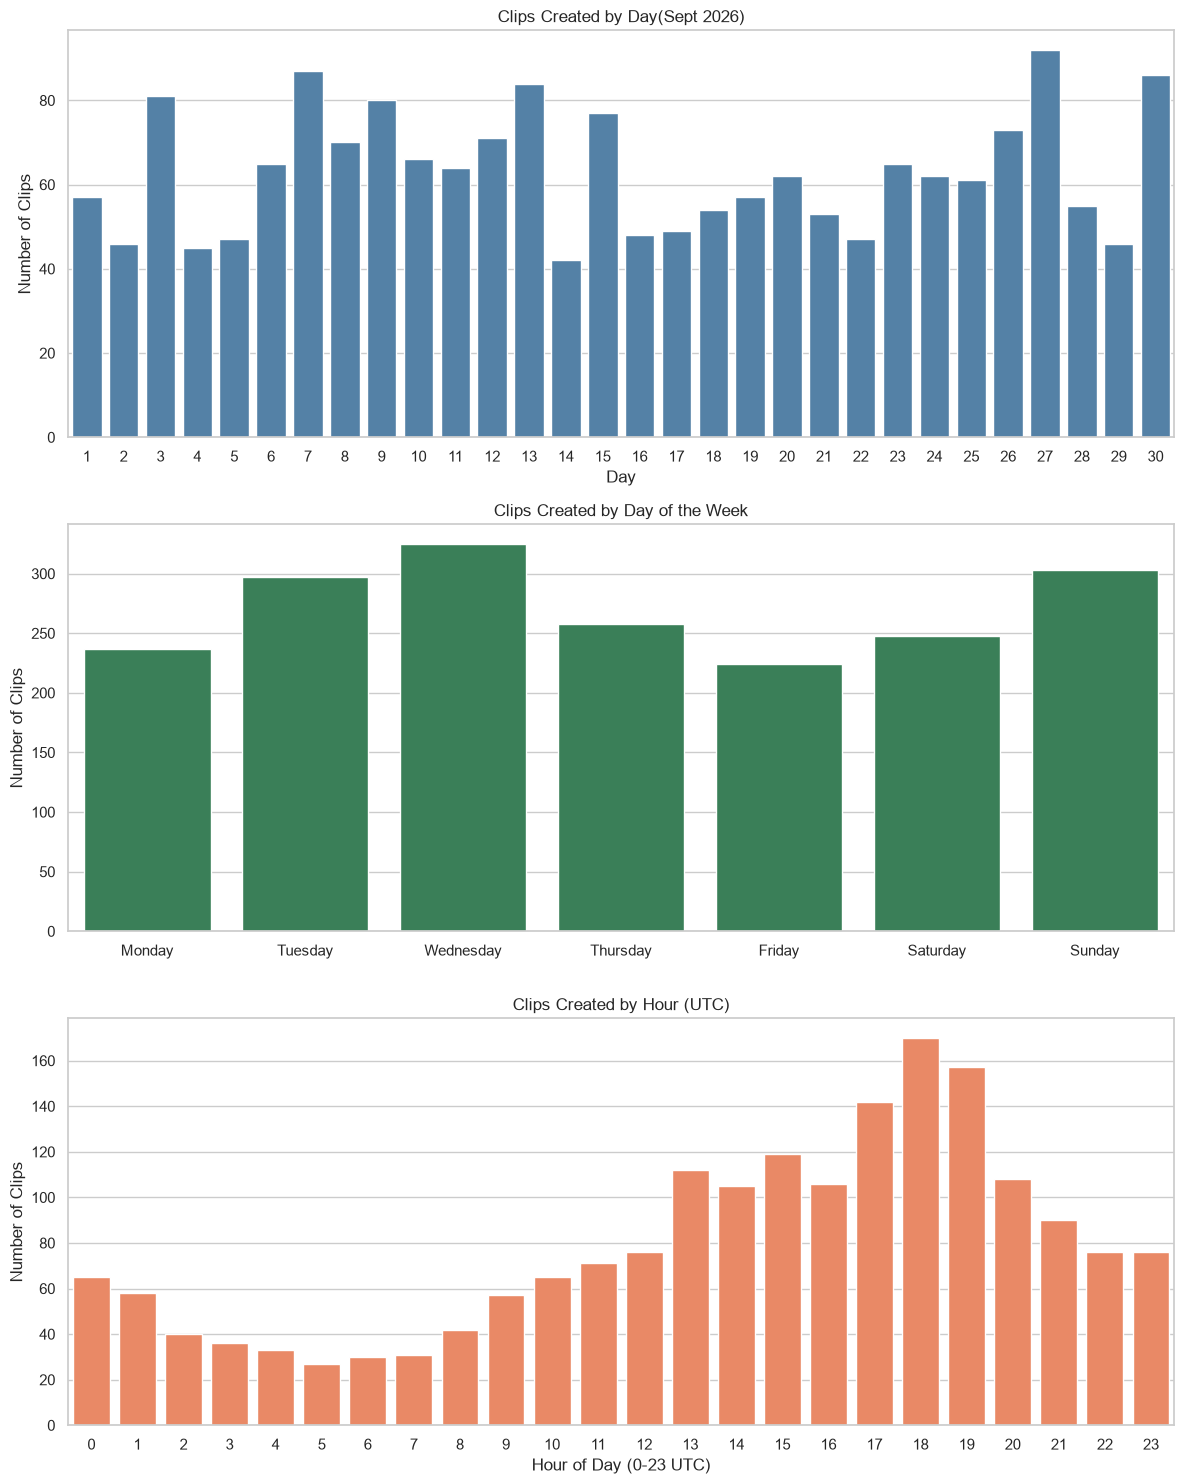

In [10]:
# lets make sure we have the correct range:
print("First clip created at :", cdf["created_at"].min())
print("Last clip created at  :", cdf["created_at"].max())

cdf['day_of_month'] = cdf['created_at'].dt.day
cdf['day_of_week'] = cdf['created_at'].dt.day_name()
cdf['hour_of_day'] = cdf['created_at'].dt.hour

fig, axes = plt.subplots(3, 1, figsize=(12, 15))
# plot daily
sns.countplot(data=cdf, x='day_of_month', color='steelblue', ax=axes[0])
axes[0].set_title('Clips Created by Day(Sept 2026)')
axes[0].set_xlabel('Day')
axes[0].set_ylabel('Number of Clips')

# plot weekly
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=cdf, x='day_of_week', order=days_order, color='seagreen', ax=axes[1])
axes[1].set_title('Clips Created by Day of the Week')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Clips')

# plot hourly
sns.countplot(data=cdf, x='hour_of_day', color='coral', ax=axes[2])
axes[2].set_title('Clips Created by Hour (UTC)')
axes[2].set_xlabel('Hour of Day (0-23 UTC)')
axes[2].set_ylabel('Number of Clips')

plt.tight_layout()
plt.show()

**Range covered:** 2026-09-01T00:09:12+00:00 to 2026-09-30T23:45:15Z. This makes sense, its what we asked for.

**Gaps:** No gaps, we visualized this.

**Cycles:** Tuesday, then wedsnday, are when most clips get made. By hour, big uptick starting at 10 untill 18, then bell curve trends downwards until midnight. High activity at start of month.

**Timezone:** Timestamps are in UTC because parsing the `created_at` column with `pd.to_datetime(..., utc=True)`.


### Exploring qualitative data

We have many qualitative variables including tags, title, content classification, is branded_content

Observations of raw data: 
- channel tags seem to allways include language(s), sometimes many languages
- content_classification labels of few categories, sometimes multiple labels

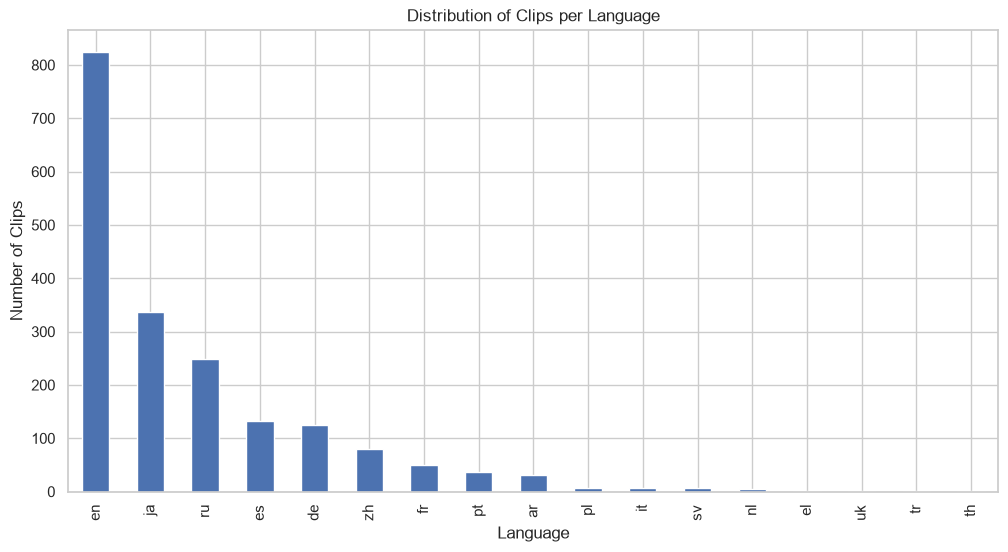

Percentage of 'ru' rows that also have 'Русский' tag: 98.02% (Count: 99/101)
Percentage of 'es' rows that also have 'Español' tag: 100.00% (Count: 41/41)
Percentage of 'ja' rows that also have '日本語' tag: 100.00% (Count: 106/106)
Percentage of 'de' rows that also have 'Deutsch' tag: 100.00% (Count: 57/57)
Percentage of 'en' rows that also have 'English' tag: 99.14% (Count: 347/350)
Percentage of 'fr' rows that also have 'Français' tag: 97.44% (Count: 38/39)
Unique tags found: 514


In [11]:
# visualized dirtibution of clips per language
plt.figure(figsize=(12, 6))
cdf["language"].value_counts().plot(kind="bar")
plt.title("Distribution of Clips per Language")
plt.xlabel("Language")
plt.ylabel("Number of Clips")
plt.show()


# investigate link between language and tags en, ru, es, ja, de
language_mappings = {
    'ru': 'Русский',
    'es': 'Español',
    'ja': '日本語',
    'de': 'Deutsch',
    'en': 'English',
    'fr': 'Français',
}

for lang_code, tag_name in language_mappings.items():
    # 1. Check for the specific language tag
    has_tag = chdf['tags'].astype(str).str.contains(f"'{tag_name}'", regex=False, na=False)
    
    # 2. Check for the specific broadcaster language code
    has_lang = chdf['broadcaster_language'].astype(str).str.strip().str.lower() == lang_code
    
    total_lang_rows = has_lang.sum()
    
    # 3. Calculate and print, ensuring we don't divide by zero
    if total_lang_rows > 0:
        count = (has_tag & has_lang).sum()
        percentage = (count / total_lang_rows) * 100
        print(f"Percentage of '{lang_code}' rows that also have '{tag_name}' tag: {percentage:.2f}% (Count: {count}/{total_lang_rows})")
    else:
        print(f"No rows found for language code '{lang_code}'.")

# calculate number of unique tags
all_tags = chdf['tags'].explode()
tag_counts = all_tags.value_counts()
print("Unique tags found:", tag_counts.shape[0])


we confirm that almost all channels have a tag that match language. We could remove tags that are related to language.


We also want to see what distribution of branded content is like per view, as well as game view distribution :

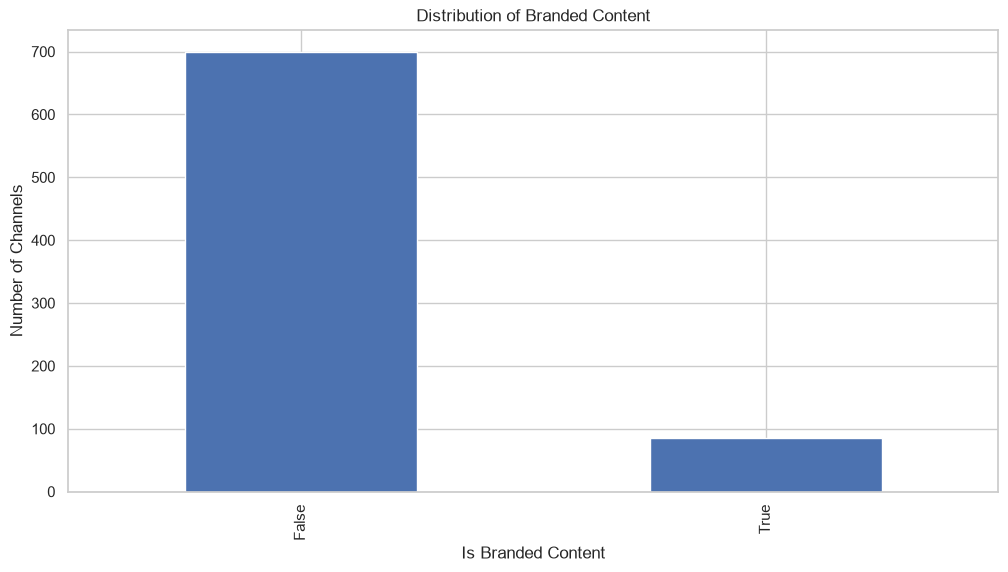

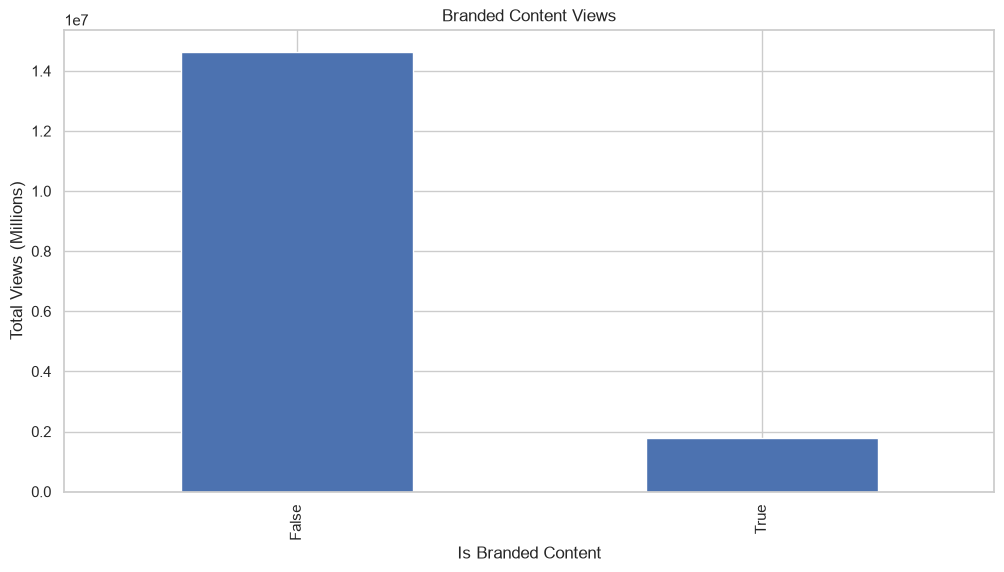

In [12]:
# branded content histogram

branded_content_counts = chdf['is_branded_content'].explode().value_counts()

plt.figure(figsize=(12, 6))
branded_content_counts.plot(kind="bar")
plt.title("Distribution of Branded Content")
plt.xlabel("Is Branded Content")
plt.ylabel("Number of Channels")
plt.show()

# branded content per view
# join channels and clips dataframes on broadcaster_id
merged_df = pd.merge(cdf, chdf, on='broadcaster_id', how='left')
branded_content_views = merged_df.groupby('is_branded_content')['view_count'].sum()

plt.figure(figsize=(12, 6))
branded_content_views.plot(kind="bar")
plt.title("Branded Content Views")
plt.xlabel("Is Branded Content")
plt.ylabel("Total Views (Millions)")
plt.show()



We also think that there mayb be some interesting effects in clip duration. There is a default clip length value, we want to check if there are lots of clips of this length:

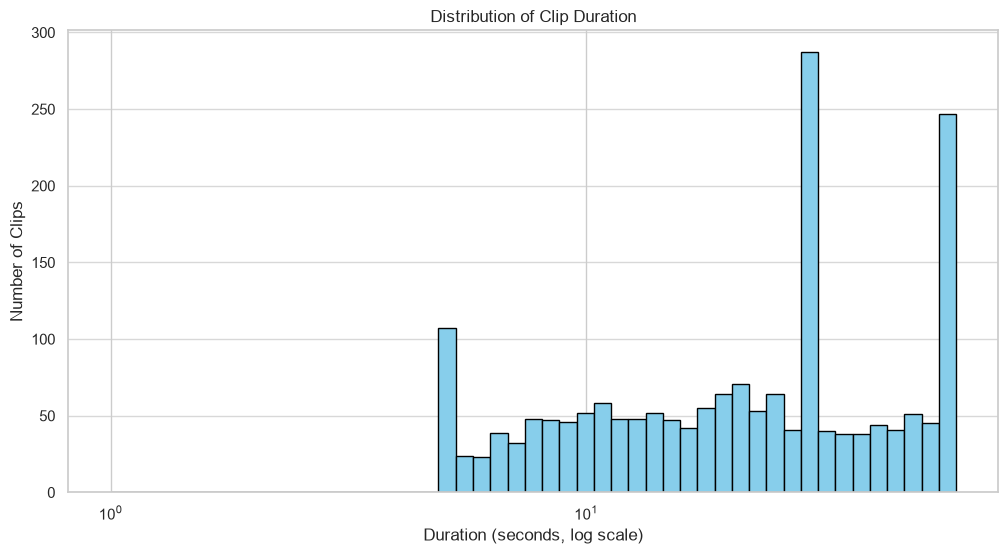

In [13]:
# check distrubtion of clip duration
plt.figure(figsize=(12, 6))
# Use a logarithmic scale for the x-axis to better visualize the distribution
plt.hist(cdf['duration'], bins=np.logspace(np.log10(1), np.log10(60), 50), color='skyblue', edgecolor='black')
plt.xscale('log')
plt.title("Distribution of Clip Duration")
plt.xlabel("Duration (seconds, log scale)")
plt.ylabel("Number of Clips")
plt.grid(axis='y', alpha=0.75)

Indeed,lots of clips are either the max of min possible length, or the default clip length.

### Checking for duplicates
Next lets check that each broadcater is represented once in channels:

In [14]:
# check for any duplicate broadcaster_id in channels dataframe
duplicate_broadcaster_ids = chdf[chdf.duplicated(subset='broadcaster_id', keep=False)]
if not duplicate_broadcaster_ids.empty:
    print("Duplicate broadcaster_id found in channels dataframe:")
    print(duplicate_broadcaster_ids[['broadcaster_id', 'title', 'game_name']])
else:
    print("No duplicate broadcaster_id found in channels dataframe.")

No duplicate broadcaster_id found in channels dataframe.


We do the same for games:

In [15]:
# check for any duplicate broadcaster_id in channels dataframe
duplicate_game_ids = gdf[gdf.duplicated(subset='id', keep=False)]
if not duplicate_game_ids.empty:
    print("Duplicate game_id found in games gdf:")
    print(duplicate_game_ids[['id', 'name']])
else:
    print("No duplicate game_id found in games gdf.")

No duplicate game_id found in games gdf.


### Duplicate game ids (Among Us)

While preparing the game-level analysis we noticed that `Among Us` appears under two game ids in the clips table: `510218` (73 clips, no name in our games table) and `919012536` (26 clips). We queried the Helix `/games` endpoint with both ids and both return the same game, "Among Us". Together they make 99 clips, which matches the sampling design (the 100 most viewed clips of each game), so this is one game whose id changed on Twitch and not two different games.

We keep `919012536` (the id that has a name in our games table) and map the old id to it, in clips and channels. Consequence: the clips cover **19 distinct games**, not 20, and Among Us has about 99 clips like the other games.

In [16]:
GAME_ID_ALIASES = {510218: 919012536}  # same game (Among Us), checked with the Helix /games endpoint

ids = list(GAME_ID_ALIASES) + list(GAME_ID_ALIASES.values())
print("clips per game id before :")
print(cdf.loc[cdf["game_id"].isin(ids), "game_id"].value_counts().to_string())
print("distinct game ids in clips before :", cdf["game_id"].nunique())

cdf["game_id"] = cdf["game_id"].replace(GAME_ID_ALIASES)
chdf["game_id"] = chdf["game_id"].replace(GAME_ID_ALIASES)
gdf = gdf[~gdf["id"].isin(list(GAME_ID_ALIASES))].reset_index(drop=True)

print("\nclips of Among Us after :", int((cdf["game_id"] == 919012536).sum()))
print("distinct game ids in clips after :", cdf["game_id"].nunique())
print("games in the games table :", gdf.shape[0])
print("games in the games table without clips :", gdf.loc[~gdf["id"].isin(cdf["game_id"].dropna()), "id"].tolist())

clips per game id before :
game_id
510218       73
919012536    26
distinct game ids in clips before : 20

clips of Among Us after : 99
distinct game ids in clips after : 19
games in the games table : 20
games in the games table without clips : [2023301131]


### Save cleaned data

In [17]:
CLEAN_DATA_DIR = Path.cwd().parent / "data/clean/"
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)

# define file paths
clean_games_path = CLEAN_DATA_DIR / "games_cleaned.parquet"
clean_clips_path = CLEAN_DATA_DIR / "clips_cleaned.parquet"
clean_channels_path = CLEAN_DATA_DIR / "channels_cleaned.parquet"

# save parquet files locally
gdf.to_parquet(clean_games_path, index=False)
cdf.to_parquet(clean_clips_path, index=False)
chdf.to_parquet(clean_channels_path, index=False)

# Mining step: clustering Twitch clips

One row = one clip. Features of the clustering: views relative to the game and duration. Tags and labels of the channel, `branded` and the language of the clip are not features: like the game and the date (local hour, weekend, day of the month), they are used only afterwards to describe (profile) the clusters.

In [25]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, completeness_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

SEED = 0
rng = np.random.default_rng(SEED)

CLEAN_DATA_DIR = Path.cwd().parent / "data/clean/"
chdf = pd.read_parquet(CLEAN_DATA_DIR / "channels_cleaned.parquet")
cdf = pd.read_parquet(CLEAN_DATA_DIR / "clips_cleaned.parquet")
gdf = pd.read_parquet(CLEAN_DATA_DIR / "games_cleaned.parquet")

# personal data is dropped at load, whatever the previous notebook did
personal = {
    "channels": (chdf, ["broadcaster_login", "broadcaster_name"]),
    "clips": (cdf, ["creator_id", "broadcaster_name", "creator_name"]),
}
chdf = chdf.drop(columns=personal["channels"][1], errors="ignore")
cdf = cdf.drop(columns=personal["clips"][1], errors="ignore")
for name, (df, cols) in personal.items():
    found = [c for c in cols if c in df.columns]
    if found:
        print(f"Dropped personal data columns from {name}: {found}")

print("channels : ", chdf.shape[0], "rows,", chdf.shape[1], "columns")
print("clips : ", cdf.shape[0], "rows,", cdf.shape[1], "columns")
print("games : ", gdf.shape[0], "rows,", gdf.shape[1], "columns")

Dropped personal data columns from channels: ['broadcaster_login', 'broadcaster_name']
Dropped personal data columns from clips: ['creator_id', 'broadcaster_name', 'creator_name']
channels :  786 rows, 8 columns
clips :  1892 rows, 11 columns
games :  20 rows, 2 columns


## Deciding what a row is

One row = one clip. Most channels have a single clip, so aggregating per channel gives statistics over one or two values. At clip level we keep all rows and the channel information (tags, labels, branded) is attached to each clip. The clip title and the clip id are not used: titles are free text written by people.

**Sampling design:** the clips are the 100 most viewed clips of each of the 20 most popular games (about 2000 clips, 1892 in the cleaned table). This shapes how every result must be read:

- the sample is selected on views, so every clip is in the right tail of its game. We can describe differences inside that tail, not what makes a clip popular in general
- clips are chosen by views, not by creation time. Older clips had more time to collect views and enter the top 100, and the hour and weekend patterns describe when *highly viewed* clips were created
- every game has about the same number of clips, so game shares inside a cluster are compared with a baseline of about 5 % (we use lift)
- channel tags and labels were read at collection time, not when the clip was made

In [26]:
chinfo = chdf[["broadcaster_id", "tags", "content_classification_labels", "is_branded_content", "broadcaster_language"]]
chinfo = chinfo.rename(columns={"broadcaster_language": "channel_language"})

clips = cdf.merge(chinfo, on="broadcaster_id", how="left", validate="many_to_one")
clips = clips.drop(columns=["title"], errors="ignore")

lang = clips["language"].astype("string").fillna(clips["channel_language"].astype("string"))
clips["lang"] = lang.str.lower().str.split("-").str[0]

print("clips :", len(clips))
print("clips without a channel row :", int(clips["tags"].isna().sum()))
print("clips without language :", int(clips["lang"].isna().sum()))
print(clips["lang"].value_counts().head(10).to_string())

clips : 1892
clips without a channel row : 0
clips without language : 0
lang
en    825
ja    336
ru    248
es    133
de    124
zh     79
fr     49
pt     37
ar     31
pl      7


## From UTC to local time

`created_at` is in UTC, so a clip made at 20h in Tokyo and one made at 20h in New York look 14 hours apart. We have no country or time zone in the data, only the language, so we map each language to one representative IANA time zone and convert every clip with it (summer time is handled by the date of the clip).

This is an approximation. Some languages are spoken in several time zones; those are listed in `AMBIGUOUS`. The local time is not a feature, so the approximation only affects how we describe the clusters (peak hour, weekend), not how they are formed. Clips with an unknown language stay in UTC.

In [27]:
LANG_TZ = {
    "en": "America/New_York", "es": "Europe/Madrid", "pt": "America/Sao_Paulo", "fr": "Europe/Paris",
    "de": "Europe/Berlin", "it": "Europe/Rome", "nl": "Europe/Amsterdam", "pl": "Europe/Warsaw",
    "cs": "Europe/Prague", "sk": "Europe/Bratislava", "hu": "Europe/Budapest", "ro": "Europe/Bucharest",
    "bg": "Europe/Sofia", "el": "Europe/Athens", "sv": "Europe/Stockholm", "da": "Europe/Copenhagen",
    "no": "Europe/Oslo", "fi": "Europe/Helsinki", "uk": "Europe/Kyiv", "ru": "Europe/Moscow",
    "tr": "Europe/Istanbul", "ar": "Asia/Riyadh", "hi": "Asia/Kolkata", "th": "Asia/Bangkok",
    "vi": "Asia/Ho_Chi_Minh", "id": "Asia/Jakarta", "ms": "Asia/Kuala_Lumpur", "tl": "Asia/Manila",
    "zh": "Asia/Shanghai", "ja": "Asia/Tokyo", "ko": "Asia/Seoul",
}
AMBIGUOUS = ["en", "es", "pt", "fr", "ar", "ru"]

tz = clips["lang"].map(LANG_TZ).fillna("UTC")
hour = pd.Series(np.nan, index=clips.index)
dow = pd.Series(np.nan, index=clips.index)
for name, idx in tz.groupby(tz).groups.items():
    lt = clips.loc[idx, "created_at"].dt.tz_convert(name)
    hour.loc[idx] = lt.dt.hour + lt.dt.minute / 60
    dow.loc[idx] = lt.dt.dayofweek

clips["hour_local"] = hour
clips["hour_sin"] = np.sin(2 * np.pi * hour / 24)
clips["hour_cos"] = np.cos(2 * np.pi * hour / 24)
clips["is_weekend"] = (dow >= 5).astype("float64")

print(f"clips with a mapped time zone : {clips['lang'].isin(LANG_TZ).mean():.1%}")
print(f"clips in an ambiguous language : {clips['lang'].isin(AMBIGUOUS).mean():.1%}")

clips with a mapped time zone : 100.0%
clips in an ambiguous language : 69.9%


## Building the feature table

**In X (the only columns k-means and DBSCAN see):**

- **views relative to the game:** `log1p(views)` minus the median of `log1p(views)` of the same game. The cut-off to enter the top 100 is different for each game, so raw views are only comparable inside a game. Because of the sampling, the game median is the median of its top 100, so the feature says how far a clip is inside the tail of its game. Games with fewer than `MIN_GAME_CLIPS` clips use the global median
- **duration:** length of the clip in seconds. Twitch clips last between 5 and 60 seconds, with many clips at the minimum, at the default length and at the maximum

Both are standardised, so X has two columns of variance 1.

**Only in the profile (binary columns, not in X):** six tag buckets (`SUPER_TAGS`: drops, competitive, vtuber/anime, irl/chill, roleplay/multiplayer, persona), the most frequent content labels, `branded`, and the language of the clip (6 most frequent plus `other`). One column per tag would be too many (most tags are rare and written in the language of the channel), so the tags are mapped by keyword to six buckets. The mapping is subjective and a clip can fall in more than one bucket. Language tags are removed because language is described separately, and the Drops tag in several languages (`DropsEnabled`, `Drops有効`, `DropsActivados`, ...) is merged first. The tags are parsed again here because in the cleaned table they are stored as one string per channel.

**Why they are out of X:** these binary columns add little variance (about 0.47 in total, against 2.0 for the two numeric columns), so k-means was already clustering essentially on views × duration. Adding tags and labels did not change the partition (ARI 0.986), nor did adding the language (ARI 0.997). Keeping them out also avoids a circular description: the clusters are described with columns that did not form them.

In [28]:
def parse_list(x):
    if x is None or (not isinstance(x, (list, tuple, np.ndarray)) and pd.isna(x)):
        return []
    items = list(x) if isinstance(x, (list, tuple, np.ndarray)) else [x]
    out = []
    for item in items:
        s = str(item)
        found = re.findall(r"'([^']*)'", s)
        out += found if found else [t.strip() for t in s.strip("[]").split(",") if t.strip()]
    return [t.lower() for t in out]


LANGUAGE_TAGS = {
    "english", "español", "日本語", "русский", "deutsch", "français", "português", "中文", "svenska", "polski",
    "türkçe", "한국어", "italiano", "العربية", "nederlands", "čeština", "українська", "suomi", "dansk", "norsk",
    "magyar", "română", "ελληνικά", "ไทย", "tiếng việt", "bahasa indonesia", "हिन्दी", "chinese中文",
}


def merge_drops(tags):
    out = []
    for t in tags:
        t = "drops" if (t.startswith("drops") or "掉宝" in t) else t
        if t not in out:
            out.append(t)
    return out


clips["tags_list"] = clips["tags"].map(parse_list).map(merge_drops)
clips["labels_list"] = clips["content_classification_labels"].map(parse_list)

# binary columns used only to describe the clusters
N_LABELS, MIN_PREV = 5, 0.05

# tags are grouped in six thematic buckets (keyword match on the lower-cased tag, language tags removed)
SUPER_TAGS = {
    "tag_drops": ["drop", "掉宝", "дроп"],
    "tag_competitive": ["rank", "comp", "esport", "tourn", "pvp", "fps", "tryhard"],
    "tag_vtuber_anime": ["vtub", "anime", "png", "weeb", "otaku", "manga"],
    "tag_irl_chill": ["irl", "chill", "chat", "asmr", "vibe", "travel", "food", "music", "雑談", "funny", "cozy"],
    "tag_rp_multiplayer": ["nopixel", "roleplay", "gtarp", "gta5rp", "multiplayer", "coop", "ストグラ", "squad"],
    "tag_persona": ["girl", "adhd", "lgbt", "feet", "bald", "educational"],
}
concept_tags = clips["tags_list"].map(lambda L: [t for t in L if t not in LANGUAGE_TAGS])
B_tags = pd.DataFrame(index=clips.index)
for name, kws in SUPER_TAGS.items():
    pattern = re.compile(r"(?:^|\b)(?:" + "|".join(map(re.escape, kws)) + r")")
    B_tags[name] = concept_tags.map(lambda L, p=pattern: float(any(p.search(t) for t in L)))

label_prev = clips["labels_list"].explode().value_counts() / len(clips)
label_cols = [t for t in label_prev.index if label_prev[t] >= MIN_PREV][:N_LABELS]


B_labels = pd.DataFrame({f"label_{t}": clips["labels_list"].map(lambda L, t=t: t in L) for t in label_cols}).astype("float64")
B_labels["branded"] = clips["is_branded_content"].astype("string").str.lower().isin(["true", "1"]).astype("float64")

lang_x = clips["lang"].where(clips["lang"].isin(["en", "ru", "ja", "de", "es", "fr"]), other="other")
B_lang = pd.get_dummies(lang_x, prefix="lang", dtype="float64")

B = pd.concat([B_tags, B_labels, B_lang], axis=1)
print(f"{B.shape[1]} binary columns for the profile (prevalence):")
print(B.mean().round(3).to_string())

15 binary columns for the profile (prevalence):
tag_drops             0.414
tag_competitive       0.085
tag_vtuber_anime      0.036
tag_irl_chill         0.079
tag_rp_multiplayer    0.035
tag_persona           0.048
label_maturegame      0.168
branded               0.110
lang_de               0.066
lang_en               0.436
lang_es               0.070
lang_fr               0.026
lang_ja               0.178
lang_other            0.094
lang_ru               0.131


In [29]:
MIN_GAME_CLIPS = 10

clips["duration"] = clips["duration"].astype("float64")
clips["log_views"] = np.log1p(clips["view_count"].astype("float64"))
game_n = clips.groupby("game_id")["log_views"].transform("size")
game_med = clips.groupby("game_id")["log_views"].transform("median")
clips["rel_views"] = clips["log_views"] - game_med.where(game_n >= MIN_GAME_CLIPS, clips["log_views"].median())

NUM_COLS = ["rel_views", "duration"]
X = (clips[NUM_COLS] - clips[NUM_COLS].mean()) / clips[NUM_COLS].std()

print("X shape :", X.shape)
print(clips[["view_count", "log_views", "rel_views", "duration"]].describe().round(2).T.to_string())

# checks, not features: correlation between the two columns of X, and clip age
age_days = (clips["created_at"].max() - clips["created_at"]).dt.total_seconds() / 86400
print(f"\nSpearman, relative views vs duration : {clips['rel_views'].corr(clips['duration'], method='spearman'):.2f}")
print(f"Spearman, relative views vs clip age : {clips['rel_views'].corr(age_days, method='spearman'):.2f}")

X shape : (1892, 2)
             count     mean      std    min      25%     50%       75%       max
view_count  1892.0  8688.36  12706.2  249.0  1982.25  4651.0  10042.75  153148.0
log_views   1892.0     8.38     1.21   5.52     7.59    8.45      9.21     11.94
rel_views   1892.0     0.18     0.62  -0.97    -0.25     0.0      0.45      3.67
duration    1892.0    26.66    17.55    4.9     11.2    23.4     35.82      60.0

Spearman, relative views vs duration : -0.05
Spearman, relative views vs clip age : -0.01


## Choosing k

The rule is fixed before looking at the clusters:

1. try k from 2 to 10, with k-means++ and 10 restarts
2. only k >= `K_MIN` are considered, because the silhouette alone tends to favour k = 2
3. stability: fit on random 80 % subsamples, predict the full table and compare with the full fit using the adjusted Rand index (ARI). A k is accepted if the mean ARI is at least `STABILITY_MIN`
4. among the accepted k, take the highest silhouette. If none is accepted, take the most stable one and say so in the report

The elbow rule is not used. Set `K_OVERRIDE` only if the choice is justified in writing.

 k  inertia  silhouette  stability
 2 2393.445       0.431      0.988
 3 1358.285       0.468      0.987
 4 1071.182       0.403      0.655
 5  834.186       0.401      0.933
 6  675.715       0.413      0.949
 7  577.750       0.417      0.933
 8  501.320       0.402      0.847
 9  450.671       0.390      0.843
10  409.275       0.384      0.746


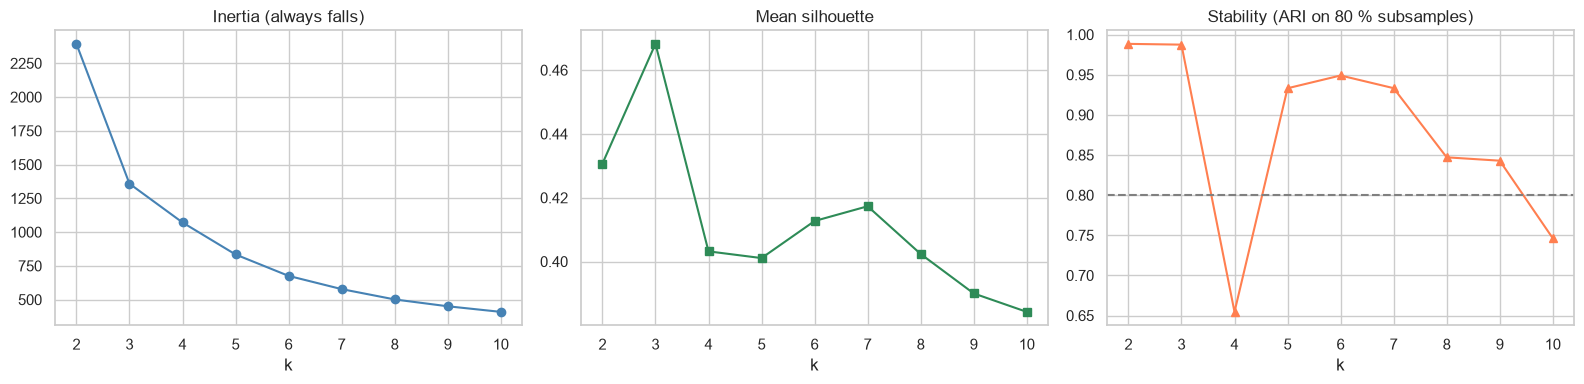

Accepted k values : [3, 5, 6, 7, 8, 9]. Highest silhouette : k = 3


In [30]:
K_RANGE = range(2, 11)
K_MIN = 3
STABILITY_MIN = 0.8
N_SUBSAMPLES = 10
SUBSAMPLE_FRAC = 0.8
K_OVERRIDE = None

rows = []
for k in K_RANGE:
    ref = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X)
    sil = silhouette_score(X, ref.labels_, sample_size=min(5000, len(X)), random_state=SEED)
    aris = []
    for b in range(N_SUBSAMPLES):
        idx = rng.choice(len(X), size=int(SUBSAMPLE_FRAC * len(X)), replace=False)
        km_b = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=b + 1).fit(X.iloc[idx])
        aris.append(adjusted_rand_score(ref.labels_, km_b.predict(X)))
    rows.append({"k": k, "inertia": ref.inertia_, "silhouette": sil, "stability": float(np.mean(aris))})

k_results = pd.DataFrame(rows)
print(k_results.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(k_results["k"], k_results["inertia"], marker="o", color="steelblue")
axes[0].set_title("Inertia (always falls)")
axes[1].plot(k_results["k"], k_results["silhouette"], marker="s", color="seagreen")
axes[1].set_title("Mean silhouette")
axes[2].plot(k_results["k"], k_results["stability"], marker="^", color="coral")
axes[2].axhline(STABILITY_MIN, color="grey", linestyle="--")
axes[2].set_title("Stability (ARI on 80 % subsamples)")
for ax in axes:
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

candidates = k_results[k_results["k"] >= K_MIN]
accepted = candidates[candidates["stability"] >= STABILITY_MIN]
if accepted.empty:
    best_k = int(candidates.sort_values("stability").iloc[-1]["k"])
    print(f"No k reaches stability {STABILITY_MIN}. Most stable one : k = {best_k}")
else:
    best_k = int(accepted.sort_values("silhouette").iloc[-1]["k"])
    print(f"Accepted k values : {list(accepted['k'])}. Highest silhouette : k = {best_k}")
if K_OVERRIDE is not None:
    best_k = K_OVERRIDE
    print("K_OVERRIDE used :", best_k)

**Choice of k:** k = 3 (silhouette 0.468, stability 0.987). It has the highest silhouette of all the k we tried, k = 2 included (0.431), so the silhouette alone would have chosen the same k. k = 4 and k = 10 do not reach the stability threshold (0.655 and 0.746). From k = 5 to 9 the stability is between 0.84 and 0.95, but the silhouette is lower (0.39 to 0.42). The silhouette is moderate, not high: the groups are not sharply separated.

In [31]:
km = KMeans(n_clusters=best_k, init="k-means++", n_init=20, random_state=SEED).fit(X)
clips["cluster"] = km.labels_

sizes = clips["cluster"].value_counts().sort_index()
print(pd.DataFrame({"n": sizes, "share_%": (sizes / sizes.sum() * 100).round(1)}).to_string())
print("\nfinal inertia :", round(km.inertia_, 1))

small = sizes[sizes / sizes.sum() < 0.02]
if len(small) > 0:
    print("\nClusters below 2 % of the clips (a cluster with no name often means a data-quality issue):", list(small.index))

clips["day_of_month"] = clips["created_at"].dt.day

g = clips.groupby("cluster")
profile = pd.DataFrame({
    "n_clips": g.size(),
    "median_views": g["view_count"].median(),
    "median_rel_views": g["rel_views"].median(),
    "median_duration": g["duration"].median(),
    "weekend_share": g["is_weekend"].mean(),
    "median_day": g["day_of_month"].median(),
    "featured_rate": g["is_featured"].apply(lambda s: s.astype("float64").mean()),
})
profile["peak_hour_local"] = (np.arctan2(g["hour_sin"].mean(), g["hour_cos"].mean()) * 24 / (2 * np.pi)) % 24
profile["hour_concentration"] = np.hypot(g["hour_sin"].mean(), g["hour_cos"].mean())
print("\nProfile of each cluster:")
profile.round(2)

            n  share_%
cluster               
0         429     22.7
1        1108     58.6
2         355     18.8

final inertia : 1358.3

Profile of each cluster:


,n_clips,median_views,median_rel_views,median_duration,weekend_share,median_day,featured_rate,peak_hour_local,hour_concentration
cluster,,,,,,,,,
0,429,4623.0,-0.03,58.1,0.28,13.0,0.10,19.93,0.34
1,1108,3801.5,-0.10,17.0,0.29,15.0,0.08,19.32,0.41
2,355,10250.0,0.99,20.5,0.30,17.0,0.09,18.84,0.41


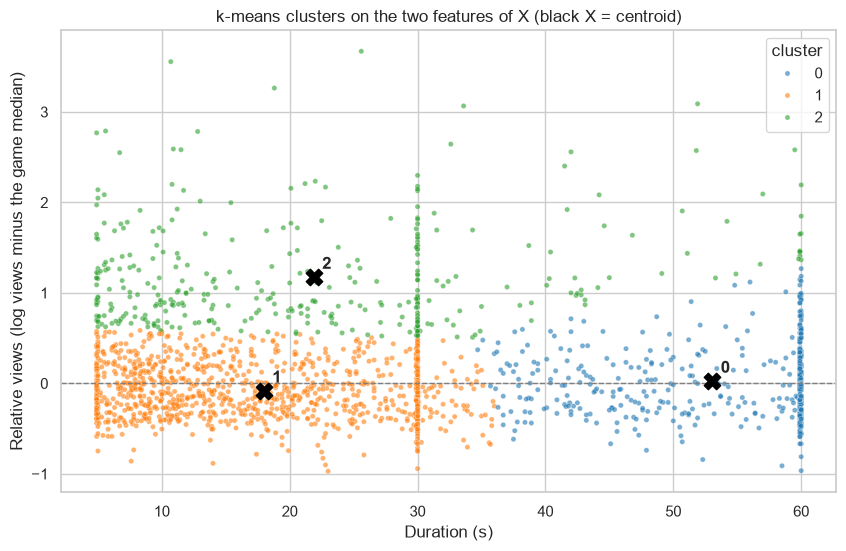

In [32]:
centers = pd.DataFrame(km.cluster_centers_ * clips[NUM_COLS].std().values + clips[NUM_COLS].mean().values, columns=NUM_COLS)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=clips, x="duration", y="rel_views", hue=clips["cluster"].astype("category"),
                palette="tab10", s=14, alpha=0.6, ax=ax)
ax.scatter(centers["duration"], centers["rel_views"], c="black", marker="X", s=140, zorder=5)
for c, row in centers.iterrows():
    ax.annotate(str(c), (row["duration"], row["rel_views"]), xytext=(6, 6), textcoords="offset points", fontweight="bold")
ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_title("k-means clusters on the two features of X (black X = centroid)")
ax.set_xlabel("Duration (s)")
ax.set_ylabel("Relative views (log views minus the game median)")
ax.legend(title="cluster")
plt.show()

### Describing the clusters with what is not in X

The tags, labels, `branded` and language columns are compared with all clips by **lift** (prevalence in the cluster / prevalence in all clips; above 1 means over-represented). Lifts of columns with fewer than 10 clips in the cluster are left empty. Every game contributes about the same number of clips, so game lift uses the same idea against a baseline of about 5 %.

In [33]:
cl = clips["cluster"]
lift = (B.groupby(cl).mean() / B.mean()).T
lift = lift.where(B.groupby(cl).sum().T >= 10)
print("Lift of the binary columns by cluster (columns = clusters):")
print(lift.round(2).to_string())

print("\ncompleteness of the clusters w.r.t. language :", round(completeness_score(clips["lang"], cl), 3))
print("completeness of the clusters w.r.t. game     :", round(completeness_score(clips["game_id"], cl), 3))

game_names = gdf.set_index("id")["name"]
overall = clips["game_id"].value_counts(normalize=True)
print("\nTop 5 games per cluster by lift (at least 10 clips):")
for c in sorted(cl.unique()):
    cnt = clips.loc[cl == c, "game_id"].value_counts()
    gl = (cnt / (cl == c).sum() / overall.reindex(cnt.index))[cnt >= 10].sort_values(ascending=False).head(5)
    print(f"  cluster {c}:", {str(game_names.get(i, i)): round(float(v), 2) for i, v in gl.items()})

Lift of the binary columns by cluster (columns = clusters):
cluster                0     1     2
tag_drops           0.87  1.02  1.09
tag_competitive     0.88  1.00  1.13
tag_vtuber_anime    1.43  0.90  0.78
tag_irl_chill       1.21  0.99  0.79
tag_rp_multiplayer  1.78  0.87   NaN
tag_persona         1.11  0.92  1.11
label_maturegame    1.22  0.96  0.85
branded             1.46  0.91  0.74
lang_de             1.00  0.98  1.07
lang_en             0.88  1.01  1.12
lang_es             0.66  0.94  1.60
lang_fr              NaN  1.15   NaN
lang_ja             1.77  0.82  0.62
lang_other          1.40  0.91  0.81
lang_ru             0.28  1.30  0.92

completeness of the clusters w.r.t. language : 0.048
completeness of the clusters w.r.t. game     : 0.066

Top 5 games per cluster by lift (at least 10 clips):
  cluster 0: {'Grand Theft Auto V': 2.72, 'Rust': 2.47, 'Slots': 1.59, 'World of Warcraft': 1.36, 'League of Legends': 1.16}
  cluster 1: {'IRL': 1.26, 'Counter-Strike': 1.26, 'Fortnite':

### Naming the groups

One line per cluster after reading the profile table, the scatter plot and the lift tables. A cluster number alone is not a result.

- **Cluster 0 -** name: long clips / what defines it: duration (median 58.1 s, close to the 60 s maximum, against 17.0 s and 20.5 s in the other clusters), with the views typical of their game (median relative views −0.03). Over-represented: Grand Theft Auto V (lift 2.72) and Rust (2.47), Japanese (1.77), `tag_rp_multiplayer` (1.78) and `branded` (1.46) / what it is not: not a high-views group and not a time of day (peak local hour 19.9, weekend 0.28)
- **Cluster 1 -** name: short clips, typical views / what defines it: the bulk of the clips (59 %), median duration 17.0 s and views slightly below the median of their game (−0.10). All its lifts are between 0.82 and 1.30, so no game, language or tag is distinctive; the largest are Russian (1.30) and IRL, Counter-Strike and Fortnite (1.26) / what it is not: not different in content, it is the "default" clip
- **Cluster 2 -** name: high-views clips / what defines it: relative views +0.99 (median 10,250 views, against 3,800 and 4,600), at any duration (median 20.5 s). Over-represented: AION 2 (1.76), Among Us (1.62) and EA Sports FC 27 (1.56), and Spanish (1.60) / what it is not: not a time of day (peak 18.8, weekend 0.30) and not a type of content (all tag lifts between 0.78 and 1.13)

The three groups come from two variables: k-means cuts the plane at about 36 s of duration and at about 0.6 of relative views (scatter plot). Peak hour and weekend are similar in the three clusters, and the completeness of the clusters against language (0.048) and against game (0.066) is close to zero, so the clusters do not recover the language or the game.

## Evaluation

Two checks, none of them needs labels: do the groups survive a change of method (DBSCAN) and are they stable (already shown in the choice of k).

### DBSCAN: density and noise

`min_samples = 2 x p` (p = number of columns of X). Epsilon is read from the k-distance plot, and we show a few quantiles because the result is sensitive.

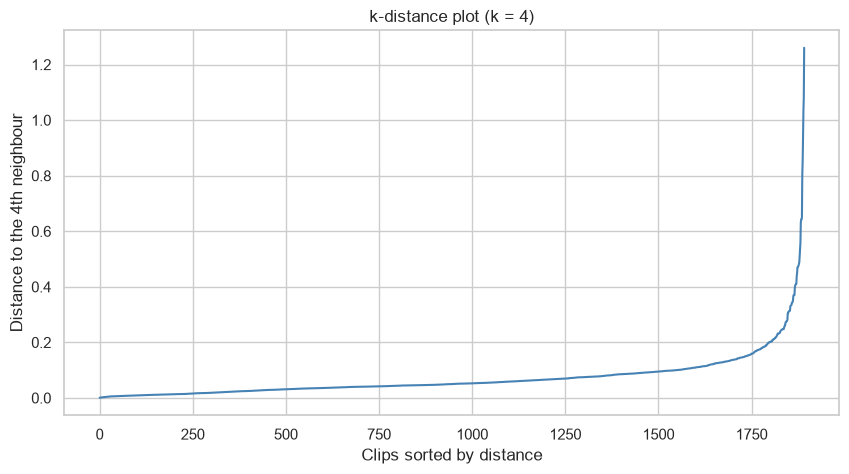

 quantile  eps  n_clusters  n_noise  noise_%
     0.80 0.10          35      257     13.6
     0.90 0.14          12      136      7.2
     0.95 0.20          10       59      3.1
     0.98 0.32           2       27      1.4


In [34]:
MIN_SAMPLES = 2 * X.shape[1]

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
dist, _ = nn.kneighbors(X)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(kdist, color="steelblue")
plt.title(f"k-distance plot (k = {MIN_SAMPLES})")
plt.xlabel("Clips sorted by distance")
plt.ylabel(f"Distance to the {MIN_SAMPLES}th neighbour")
plt.show()

rows = []
for q in [0.80, 0.90, 0.95, 0.98]:
    eps = float(np.quantile(kdist, q))
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    rows.append({"quantile": q, "eps": round(eps, 2), "n_clusters": len(set(lab) - {-1}),
                 "n_noise": int((lab == -1).sum()), "noise_%": round((lab == -1).mean() * 100, 1)})
print(pd.DataFrame(rows).to_string(index=False))

In [35]:
DBSCAN_QUANTILE = 0.90

eps = float(np.quantile(kdist, DBSCAN_QUANTILE))
clips["dbscan"] = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)

print("eps :", round(eps, 2), " min_samples :", MIN_SAMPLES)
print(clips["dbscan"].value_counts().sort_index().to_string())
print("\nk-means clusters (rows) vs DBSCAN labels (columns), -1 is noise:")
print(pd.crosstab(clips["cluster"], clips["dbscan"]).to_string())

if (clips["dbscan"] == -1).any():
    cols = ["view_count", "rel_views", "duration", "hour_local", "is_weekend"]
    noise_profile = pd.DataFrame({
        "noise": clips.loc[clips["dbscan"] == -1, cols].median(),
        "not_noise": clips.loc[clips["dbscan"] != -1, cols].median(),
    })
    print("\nMedians of noise vs the rest:")
    print(noise_profile.round(2).to_string())

eps : 0.14  min_samples : 4
dbscan
-1      136
 0     1681
 1        8
 2       17
 3        4
 4        8
 5        4
 6        6
 7        5
 8        9
 9        6
 10       4
 11       4

k-means clusters (rows) vs DBSCAN labels (columns), -1 is noise:
dbscan   -1     0    1    2    3    4    5    6    7    8    9    10   11
cluster                                                                  
0         34   381    0    0    4    0    4    0    5    0    1    0    0
1         14  1089    0    0    0    0    0    0    0    0    5    0    0
2         88   211    8   17    0    8    0    6    0    9    0    4    4

Medians of noise vs the rest:
              noise  not_noise
view_count  10048.5     4542.0
rel_views      1.21      -0.02
duration      33.45       22.8
hour_local    16.92      16.96
is_weekend      0.0        0.0


**Choice of epsilon and what DBSCAN adds:** quantile 0.90 (eps 0.14). At 0.80 the clips break into 35 clusters with 13.6 % of noise; at 0.95 and 0.98 the noise is only 3.1 % and 1.4 %, but there are fewer clusters (10 and 2); 0.90 gives 12 clusters and 7.2 % of noise. Even so, the result is one dense region with 1,681 clips (89 %), 11 small clusters of 4 to 17 clips and 136 noise clips. The noise sits in the upper tail of the views (median relative views 1.21 against −0.02, median views 10,049 against 4,542; 88 of the 136 are in k-means cluster 2) and the clips are somewhat longer than the rest (median 33.5 s against 22.8 s; 34 of the 136 are in cluster 0). The dense regions do not agree with k-means: the large DBSCAN cluster contains clips of the three k-means clusters (381, 1,089 and 211), so the k-means groups are not separated by gaps in density, they cut a continuous cloud.

In [36]:
# Save the cluster of each clip with the parsed tags and labels of its channel, so the frequent itemsets
# can be computed inside each cluster. No ids of people are kept besides `broadcaster_id`.
CLUSTERS_PATH = CLEAN_DATA_DIR / "clip_clusters.parquet"

out = clips[["broadcaster_id", "game_id", "lang", "view_count", "rel_views", "duration", "hour_local", "is_weekend",
             "is_featured", "tags_list", "labels_list", "cluster", "dbscan"]].reset_index(drop=True)
out.to_parquet(CLUSTERS_PATH, index=False)
print("saved", out.shape, "to", CLUSTERS_PATH)

saved (1892, 13) to /home/rambo/M1AI/DATA_ACQ/twitch_live_datacq/data/clean/clip_clusters.parquet


## Summary of findings

**What a row is:** one clip; 1,892 clips

**Features:** two numeric columns, views relative to the game and duration (standardised). Tags, labels, `branded`, language, game and date are not features: they are only used in the profile

**Robustness of the feature choice:** the clustering uses 2 numeric variables; including tags and labels as binary columns did not change the partition (ARI 0.986), nor did including language (ARI 0.997), so they were used only for the description

**Time zone:** language mapped to a representative IANA zone (ambiguous: en, es, pt, fr, ar, ru); only used to describe the clusters (peak hour, weekend), not to build them

**k and why:** rule fixed before looking (silhouette among stable k >= 3); result: k = 3 (silhouette 0.468, stability 0.987), which is also the highest silhouette over all k; k = 4 is the only small k that is unstable (0.655)

**Clusters:**

- **Long clips** (429 clips, 23 %): median duration 58 s, typical views for the game; Grand Theft Auto V and Rust over-represented
- **Short clips, typical views** (1,108 clips, 59 %): median duration 17 s, no distinctive game, language or tag
- **High-views clips** (355 clips, 19 %): median relative views +0.99 (10,250 views), at any duration; AION 2, Among Us and EA Sports FC 27 over-represented

The groups come from two variables (views relative to the game and duration). Hour, weekend, language and game do not separate them.

**Agreement and noise:** DBSCAN (quantile 0.90, eps 0.14) finds one dense region with 89 % of the clips, 11 small clusters of 4 to 17 clips and 136 noise clips (7.2 %), mostly in the upper tail of the views. The k-means groups are not separated by gaps in density

**Limitations:** the sample is the 100 most viewed clips of the 20 most popular games, so conclusions are about the right tail only; older clips had more time to enter the top 100, and hour and weekend describe highly viewed clips; no follower count, so views depend on the size of the channel; one month; time zone is inferred from the language; channel tags are from collection time; clips of the same channel share tags and labels, so rows are not independent

**Personal data:** names, logins and creator information are dropped at load; clip titles are not used; `broadcaster_id` and the channel tags are kept for the itemsets